In [1]:
%matplotlib inline

import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch

import cute_rmsnorm
import triton_rmsnorm
import tilelang_rmsnorm
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

M, N = 4096, 4096
EPS = cute_rmsnorm.EPS  # the CUDA kernel hardcodes the same value


def rmsnorm(x, w):
    return torch.nn.functional.rms_norm(x, (x.shape[-1],), w, EPS)

In [2]:
AUTOTUNE = True  # False runs each kernel with its own defaults

TRITON_KERNEL = triton_rmsnorm.rmsnorm_kernel(autotune=AUTOTUNE)

IMPLEMENTATIONS = {
    "torch": make_runner("torch", rmsnorm),
    "torch_compile": make_runner("torch_compile", lambda x, w: x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + EPS) * w),
    "triton": make_runner(
        "triton",
        TRITON_KERNEL,
        extra_args=lambda x, w, out: (x.stride(0), x.shape[1], EPS),
        grid=lambda meta: (meta["x_ptr"].shape[0],),
    ),
    "tilelang": make_runner(
        "tilelang", tilelang_rmsnorm.rmsnorm_,
        specialize=lambda kernel, x, w: kernel(*x.shape, dtype=str(x.dtype).removeprefix("torch.")),
        name="rmsnorm",
    ),
    "cute": make_runner("cute", cute_rmsnorm.rmsnorm(autotune=AUTOTUNE)),
    "cute_vec": make_runner("cute", cute_rmsnorm.rmsnorm_vec(autotune=AUTOTUNE)),
    "cuda": make_runner("cuda", "cuda_rmsnorm.cu", entry="rmsnorm"),
}

In [3]:
# Tests: row lengths around block and vector boundaries. cute_vec needs N % 4 == 0.
for m, n in [(1, 1), (3, 7), (5, 255), (2, 256), (3, 257), (7, 1000), (4, 4096), (3, 8196), (M, N)]:
    inputs = make_inputs((m, n), (n,))
    for name, fn in IMPLEMENTATIONS.items():
        if name == "cute_vec" and n % 4:
            continue
        torch.testing.assert_close(fn(*inputs), rmsnorm(*inputs), msg=f"{name}, {m}x{n}")

# Test the public TileLang wrapper, including FP32 accumulation for low precision.
for dtype in (torch.float32, torch.float16, torch.bfloat16):
    for n in (1, 257, 4096, 8196):
        x = torch.randn(3, n, device="cuda", dtype=dtype)
        w = torch.randn(n, device="cuda", dtype=dtype)
        expected = (x.float() * torch.rsqrt(x.float().square().mean(-1, keepdim=True) + EPS) * w.float()).to(dtype)
        torch.testing.assert_close(tilelang_rmsnorm.rmsnorm(x, w), expected)
    x = torch.zeros(2, 257, device="cuda", dtype=dtype)
    torch.testing.assert_close(tilelang_rmsnorm.rmsnorm(x, w[:257].contiguous()), x)
x = torch.empty(0, 257, device="cuda")
assert tilelang_rmsnorm.rmsnorm(x, torch.ones(257, device="cuda")).shape == x.shape
print("OK")

/home/dkuznedelev/ysda-dsl-benches/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


2026-11-13 14:17:33  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:137): TileLang begins to compile kernel `rmsnorm_kernel` with `out_idx=None`


2026-11-13 14:17:35  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:145): TileLang completes to compile kernel `rmsnorm_kernel`


2026-11-13 14:17:39  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:137): TileLang begins to compile kernel `rmsnorm_kernel` with `out_idx=None`


2026-11-13 14:17:41  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:145): TileLang completes to compile kernel `rmsnorm_kernel`


2026-11-13 14:17:48  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:137): TileLang begins to compile kernel `rmsnorm_kernel` with `out_idx=None`


... (31 outputs left out)

2026-11-13 14:18:56  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:145): TileLang completes to compile kernel `rmsnorm_kernel`


2026-11-13 14:18:57  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:137): TileLang begins to compile kernel `rmsnorm_kernel` with `out_idx=None`


2026-11-13 14:18:57  [TileLang:tilelang.jit.kernel:INFO] (kernel.py:145): TileLang completes to compile kernel `rmsnorm_kernel`


OK


         torch: 34.512 us (p20-p80: 34.003-35.878) | 1.944508 TFLOP/s | 3889.49 GB/s | 1.25x
 torch_compile: 43.104 us (p20-p80: 42.944-44.653) | 1.556906 TFLOP/s | 3114.19 GB/s | 1.00x
        triton: 28.480 us (p20-p80: 27.610-28.730) | 2.356350 TFLOP/s | 4713.28 GB/s | 1.51x
      tilelang: 23.968 us (p20-p80: 23.584-24.429) | 2.799936 TFLOP/s | 5600.56 GB/s | 1.80x
          cute: 36.832 us (p20-p80: 36.077-36.992) | 1.822026 TFLOP/s | 3644.50 GB/s | 1.17x
      cute_vec: 30.688 us (p20-p80: 30.387-30.816) | 2.186811 TFLOP/s | 4374.16 GB/s | 1.40x
          cuda: 52.352 us (p20-p80: 52.160-52.787) | 1.281878 TFLOP/s | 2564.07 GB/s | 0.82x


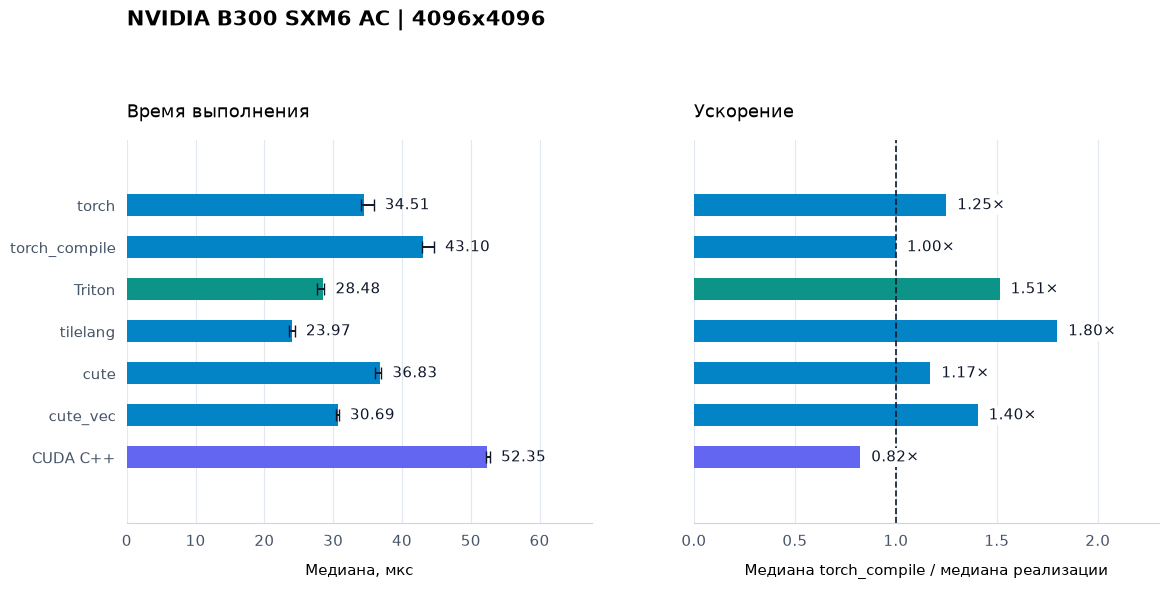

triton config: BLOCK_SIZE: 4096, num_warps: 16, num_ctas: 1, num_stages: 3, maxnreg: None


cute config: {'threads_per_block': 128}


cute_vec config: {'threads_per_block': 256}


In [4]:
inputs = make_inputs((M, N), (N,))
# square, add, multiply by 1/rms, multiply by w
results = run_benchmark(IMPLEMENTATIONS, inputs, reference=rmsnorm, flops=4 * M * N)
plot_benchmark(results, baseline="torch_compile", title=f"{torch.cuda.get_device_name()} | {M}x{N}")
plt.show()
if AUTOTUNE:
    print("triton config:", TRITON_KERNEL.best_config)
    print("cute config:", IMPLEMENTATIONS["cute"].asm()["rmsnorm"]["config"])
    print("cute_vec config:", IMPLEMENTATIONS["cute_vec"].asm()["rmsnorm_vec"]["config"])

In [5]:
for name, fn in IMPLEMENTATIONS.items():
    dump_asm(fn.asm(), Path("asm") / name)
    print(name, list(fn.asm()))

torch []


torch_compile ['triton_poi_fused_add_mean_mul_pow_rsqrt_0', 'triton_red_fused_add_mean_mul_pow_rsqrt_0']


triton ['rmsnorm_kernel']


tilelang ['rmsnorm']


cute ['rmsnorm']


cute_vec ['rmsnorm_vec']


cuda ['cuda_rmsnorm']
